In [ ]:
#Spatiotemporal Moran Index for 15 types of Weights

In [ ]:
#A) Evaluation of Moran (Moran-2Di for WST+ Moran’s I each year for Wbd) + Monte Carlo + CI95

In [1]:
# 1) Install & Upload

!pip -q install numpy pandas openpyxl

# Mengunggah file dataset langsung lewat prompt kode
from google.colab import files
print("Silakan pilih dan upload semua file dataset (.xlsx) yang diperlukan:")
uploaded = files.upload()

Silakan pilih dan upload semua file dataset (.xlsx) yang diperlukan:


Saving W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx to W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx
Saving data_JarakCentroid_10th_Pendidikan.xlsx to data_JarakCentroid_10th_Pendidikan.xlsx
Saving data_JarakCentroid_10th_Kesehatan.xlsx to data_JarakCentroid_10th_Kesehatan.xlsx
Saving data_JarakCentroid_10th_TPT.xlsx to data_JarakCentroid_10th_TPT.xlsx


In [5]:
# 2) Load data for all 3 fields

import numpy as np
import pandas as pd

W8_PATH = "W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx"

datasets = {
    "TPT": "data_JarakCentroid_10th_TPT.xlsx",
    "Kesehatan": "data_JarakCentroid_10th_Kesehatan.xlsx",
    "Pendidikan": "data_JarakCentroid_10th_Pendidikan.xlsx"
}

dfs = {}
for field, path in datasets.items():
    dfs[field] = pd.read_excel(path)
    print(f"=== Field: {field} ===")
    print("Columns:", dfs[field].columns.tolist())
    print("Shape:", dfs[field].shape)
    print("Year counts:", dfs[field]["Waktu"].value_counts().sort_index().to_dict())
    print()

=== Field: TPT ===
Columns: ['Waktu', 'Lokasi', 'Y', 'Y_(t-1)']
Shape: (350, 4)
Year counts: {2015: 35, 2017: 35, 2018: 35, 2019: 35, 2020: 35, 2021: 35, 2022: 35, 2023: 35, 2024: 35, 2025: 35}

=== Field: Kesehatan ===
Columns: ['Waktu', 'Lokasi', 'Y', 'Y_(t-1)']
Shape: (350, 4)
Year counts: {2016: 35, 2017: 35, 2018: 35, 2019: 35, 2020: 35, 2021: 35, 2022: 35, 2023: 35, 2024: 35, 2025: 35}

=== Field: Pendidikan ===
Columns: ['Waktu', 'Lokasi', 'Y', 'Y_(t-1)']
Shape: (350, 4)
Year counts: {2014: 35, 2015: 35, 2016: 35, 2017: 35, 2018: 35, 2019: 35, 2020: 35, 2021: 35, 2022: 35, 2023: 35}



In [6]:
#3) Function of (Moran-type) Index and Monte Carlo permutation + CI95

import numpy as np
import pandas as pd

def moran_index(z_vec: np.ndarray, W: np.ndarray) -> float:
    """
    Moran-type index:
    I = (n/S0) * (z' W z) / (z' z)
    Works for both n=175 (W_ST) and n=35 (W_bd per-year).
    """
    z_col = np.asarray(z_vec, dtype=float).reshape(-1, 1)
    n = z_col.shape[0]
    S0 = float(W.sum())
    if S0 == 0:
        raise ValueError("S0 = sum(W) is zero.")
    num = float((z_col.T @ W @ z_col)[0, 0])
    den = float((z_col.T @ z_col)[0, 0])
    return (n / S0) * (num / den)


def mc_perm_ci(
    z_vec: np.ndarray,
    W: np.ndarray,
    n_perm: int = 1000,
    seed: int = 2026,
    two_sided: bool = True,
):
    """
    Monte Carlo permutation test (unrestricted permutation of labels).
    Returns I_obs, p_value, perm_mean, perm_std, ci95_low, ci95_high
    """
    rng = np.random.default_rng(seed)
    z_vec = np.asarray(z_vec, dtype=float).ravel()

    I_obs = moran_index(z_vec, W)

    I_perm = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        z_perm = rng.permutation(z_vec)
        I_perm[b] = moran_index(z_perm, W)

    if two_sided:
        p_value = (np.sum(np.abs(I_perm) >= np.abs(I_obs)) + 1) / (n_perm + 1)
    else:
        p_value = (np.sum(I_perm >= I_obs) + 1) / (n_perm + 1)

    perm_mean = float(I_perm.mean())
    perm_std  = float(I_perm.std(ddof=1))
    ci95_low  = float(np.percentile(I_perm, 2.5))
    ci95_high = float(np.percentile(I_perm, 97.5))

    return I_obs, p_value, perm_mean, perm_std, ci95_low, ci95_high


def mc_perm_ci_within_year(
    z_vec: np.ndarray,
    years_vec: np.ndarray,
    W_ST: np.ndarray,
    n_perm: int = 1000,
    seed: int = 2026,
    two_sided: bool = True
):
    """
    Monte Carlo permutation test for Moran-2Di with within-year permutation.
    W_ST fixed (175x175), shuffle z within each year.
    """
    rng = np.random.default_rng(seed)
    z_vec = np.asarray(z_vec, dtype=float).ravel()
    years_vec = np.asarray(years_vec).ravel()

    I_obs = moran_index(z_vec, W_ST)

    unique_years = np.unique(years_vec)
    year_indices = {yr: np.where(years_vec == yr)[0] for yr in unique_years}

    I_perm = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        z_perm = z_vec.copy()
        for yr, idx in year_indices.items():
            z_perm[idx] = rng.permutation(z_perm[idx])
        I_perm[b] = moran_index(z_perm, W_ST)

    if two_sided:
        p_value = (np.sum(np.abs(I_perm) >= np.abs(I_obs)) + 1) / (n_perm + 1)
    else:
        p_value = (np.sum(I_perm >= I_obs) + 1) / (n_perm + 1)

    perm_mean = float(I_perm.mean())
    perm_std  = float(I_perm.std(ddof=1))
    ci95_low  = float(np.percentile(I_perm, 2.5))
    ci95_high = float(np.percentile(I_perm, 97.5))

    return I_obs, p_value, perm_mean, perm_std, ci95_low, ci95_high

In [4]:
# 4) Processing 13 sheets of WST(350x350) + 1 sheet Wbd(35x35) across all fields

sheets_needed = [
    "W_ST^Q",
    "W_ST^Q10",
    "W_ST^Q10q",
    "W_ST^Q10r",
    "W_ST^Qq",
    "W_ST^Qr",
    "W_ST^iq",
    "W_bdst",
    "Wseragam_diag1",
    "Wseragam_diag0",
    "Wacak_diag1",
    "Wacak_diag0",
    "W_bd"
]

xls = pd.ExcelFile(W8_PATH)
print("Sheets found:", xls.sheet_names)

all_res_st = {}

for field, df_field in dfs.items():
    print(f"Processing W_ST for {field}...")
    res_st = []

    y = df_field["Y"].astype(float).to_numpy()
    z = (y - y.mean()) / y.std(ddof=0)
    years = df_field["Waktu"].to_numpy()
    N = len(z)

    for sh in sheets_needed:
        if sh not in xls.sheet_names:
            print(f"[MISSING] {sh} not found in {W8_PATH}")
            continue

        Wmat = pd.read_excel(W8_PATH, sheet_name=sh, header=None).to_numpy(dtype=float)

        if sh != "W_bd":
            if Wmat.shape != (N, N):
                print(f"[SKIP] {sh} shape {Wmat.shape} != ({N},{N})")
                continue

            I_obs, pval, pmean, pstd, ciL, ciH = mc_perm_ci_within_year(
                z, years, Wmat,
                n_perm=1000, seed=2026, two_sided=True
            )
            res_st.append({
                "Weight": sh,
                "I_obs": I_obs,
                "p_value": pval,
                "perm_mean": pmean,
                "perm_std": pstd,
                "ci95_low": ciL,
                "ci95_high": ciH
            })

    all_res_st[field] = pd.DataFrame(res_st).sort_values("Weight").reset_index(drop=True)
    print(f"Finished W_ST for {field}.")

# Display TPT as an example
display(all_res_st["TPT"])

Sheets found: ['W_ST^Q', 'W_ST^Q10', 'W_ST^Qq', 'W_ST^Q10q', 'W_ST^Qr', 'W_ST^Q10r', 'W_ST^iq', 'W_bdst', 'W_bd', 'Wseragam_diag0', 'Wseragam_diag1', 'Wacak_diag0', 'Wacak_diag1']
Processing W_ST for TPT...
Finished W_ST for TPT.
Processing W_ST for Kesehatan...
Finished W_ST for Kesehatan.
Processing W_ST for Pendidikan...
Finished W_ST for Pendidikan.


,Weight,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_ST^Q,0.665860,0.000999,0.397693,0.016116,0.366083,0.429262
1,W_ST^Q10,0.691172,0.000999,0.397706,0.016250,0.365648,0.429440
2,W_ST^Q10q,0.760292,0.000999,0.383351,0.020225,0.343675,0.424077
3,W_ST^Q10r,0.800831,0.000999,0.405870,0.020288,0.365316,0.444883
4,W_ST^Qq,0.783447,0.000999,0.397294,0.019991,0.358008,0.435997
5,W_ST^Qr,0.790093,0.000999,0.397269,0.020211,0.356497,0.437161
6,W_ST^iq,0.518330,0.000999,0.080711,0.024810,0.031863,0.128741
7,W_bdst,0.725056,0.000999,0.397678,0.016720,0.364863,0.429743
8,Wacak_diag0,0.132161,0.000999,0.103498,0.005800,0.092203,0.115227
9,Wacak_diag1,0.179013,0.000999,0.151896,0.005487,0.141211,0.162992


In [7]:
# 5) Special for Wbd(35x35): Moran's I Per Year across all fields

import numpy as np
import pandas as pd

all_res_bd_year = {}

if "W_bd" in xls.sheet_names:
    W_bd = pd.read_excel(W8_PATH, sheet_name="W_bd", header=None).to_numpy(dtype=float)

    if W_bd.shape != (35, 35):
        print(f"[WARN] W_bd shape is {W_bd.shape}, expected (35,35)")
    else:
        for field, df_field in dfs.items():
            print(f"Processing W_bd for {field}...")
            res_bd_year = []

            for yr in sorted(df_field["Waktu"].unique()):
                df_y = df_field[df_field["Waktu"] == yr].copy()

                y_yr = df_y["Y"].astype(float).to_numpy()
                z_yr = (y_yr - y_yr.mean()) / y_yr.std(ddof=0)

                I_obs, pval, pmean, pstd, ciL, ciH = mc_perm_ci(
                    z_yr, W_bd,
                    n_perm=1000, seed=2026, two_sided=True
                )
                res_bd_year.append({
                    "Weight": "W_bd",
                    "Year": int(yr),
                    "I_obs": I_obs,
                    "p_value": pval,
                    "perm_mean": pmean,
                    "perm_std": pstd,
                    "ci95_low": ciL,
                    "ci95_high": ciH
                })

            all_res_bd_year[field] = pd.DataFrame(res_bd_year).sort_values("Year").reset_index(drop=True)

# Display TPT as an example
display(all_res_bd_year["TPT"])

Processing W_bd for TPT...
Processing W_bd for Kesehatan...
Processing W_bd for Pendidikan...


,Weight,Year,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_bd,2015,0.163700,0.006993,-0.029356,0.039840,-0.088999,0.059682
1,W_bd,2017,0.308738,0.000999,-0.031230,0.038182,-0.090090,0.064254
2,W_bd,2018,0.314820,0.000999,-0.029548,0.038570,-0.088284,0.067931
3,W_bd,2019,0.334749,0.000999,-0.029258,0.041067,-0.090645,0.081783
4,W_bd,2020,0.127120,0.004995,-0.030988,0.039359,-0.086857,0.073560
5,W_bd,2021,0.152689,0.005994,-0.029922,0.039986,-0.087763,0.062414
6,W_bd,2022,0.199603,0.001998,-0.029549,0.039776,-0.090496,0.067705
7,W_bd,2023,0.352367,0.000999,-0.029536,0.038780,-0.087287,0.066716
8,W_bd,2024,0.403188,0.000999,-0.030342,0.037695,-0.090276,0.058820
9,W_bd,2025,0.401109,0.000999,-0.030381,0.037417,-0.089444,0.057811


In [8]:
# 6) Export results for all fields

from google.colab import files

for field in dfs.keys():
    st_file = f"moran2di_mc_summary_WST_{field}_centroid_1000rep_10th.csv"
    bd_file = f"moranI_mc_summary_Wbd_by_year_{field}_centroid_1000rep_10th.csv"

    all_res_st[field].to_csv(st_file, index=False)
    all_res_bd_year[field].to_csv(bd_file, index=False)

    files.download(st_file)
    files.download(bd_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Visualization of Monte Carlo Permutation Results

The following is a visualization of the Monte Carlo permutation results for the WST and Wbd weights.

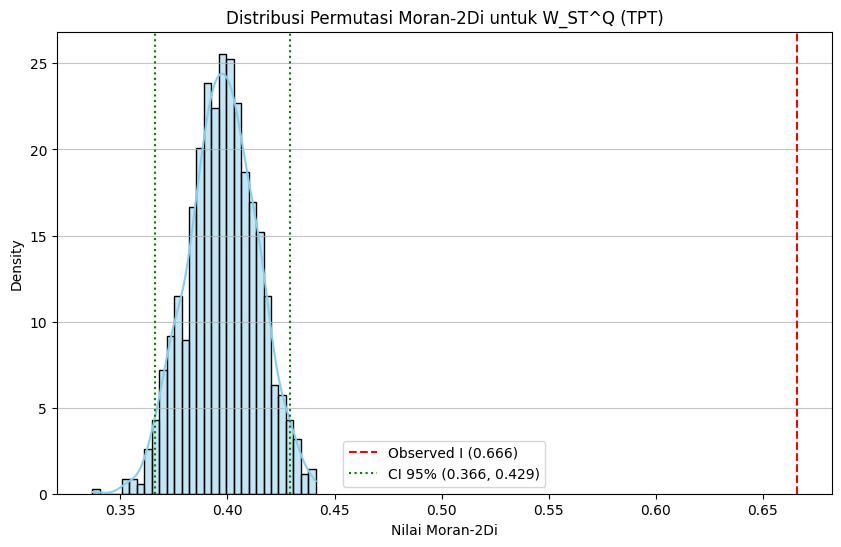

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# --- Visualization for W_ST (example: TPT dengan W_ST^Q_diag1) ---
target_field = 'TPT'
target_weight = 'W_ST^Q'

# Ambil data hasil yang sudah disimpan dalam dictionary all_res_st
res_st_df = all_res_st[target_field]
w_st_q_data = res_st_df[res_st_df['Weight'] == target_weight].iloc[0]
ob_I_st_q = w_st_q_data['I_obs']
ciL_st_q = w_st_q_data['ci95_low']
ciH_st_q = w_st_q_data['ci95_high']

# Memuat matriks pembobot W_ST yang bersesuaian
W_ST_Q_mat = pd.read_excel(W8_PATH, sheet_name=target_weight, header=None).to_numpy(dtype=float)

rng = np.random.default_rng(2026)
n_perm = 1000
I_perm_st_q = np.empty(n_perm, dtype=float)

# Gunakan data tahun dan variabel z spesifik untuk target_field
df_field = dfs[target_field]
y_val = df_field["Y"].astype(float).to_numpy()
z_val = (y_val - y_val.mean()) / y_val.std(ddof=0)
years_val = df_field["Waktu"].to_numpy()

unique_years = np.unique(years_val)
year_indices = {yr: np.where(years_val == yr)[0] for yr in unique_years}

for b in range(n_perm):
    z_perm = z_val.copy()
    for yr, idx in year_indices.items():
        z_perm[idx] = rng.permutation(z_perm[idx])
    I_perm_st_q[b] = moran_index(z_perm, W_ST_Q_mat)

plt.figure(figsize=(10, 6))
sns.histplot(I_perm_st_q, bins=30, kde=True, color='skyblue', stat='density')
plt.axvline(ob_I_st_q, color='red', linestyle='--', label=f'Observed I ({ob_I_st_q:.3f})')
plt.axvline(ciL_st_q, color='green', linestyle=':', label=f'CI 95% ({ciL_st_q:.3f}, {ciH_st_q:.3f})')
plt.axvline(ciH_st_q, color='green', linestyle=":")
plt.title(f'Distribusi Permutasi Moran-2Di untuk {target_weight} ({target_field})')
plt.xlabel('Nilai Moran-2Di')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

### Visualisasi untuk W_bd (per Tahun)

Untuk bobot W_bd, kita akan melihat distribusi permutasi untuk setiap tahun (2018-2022).

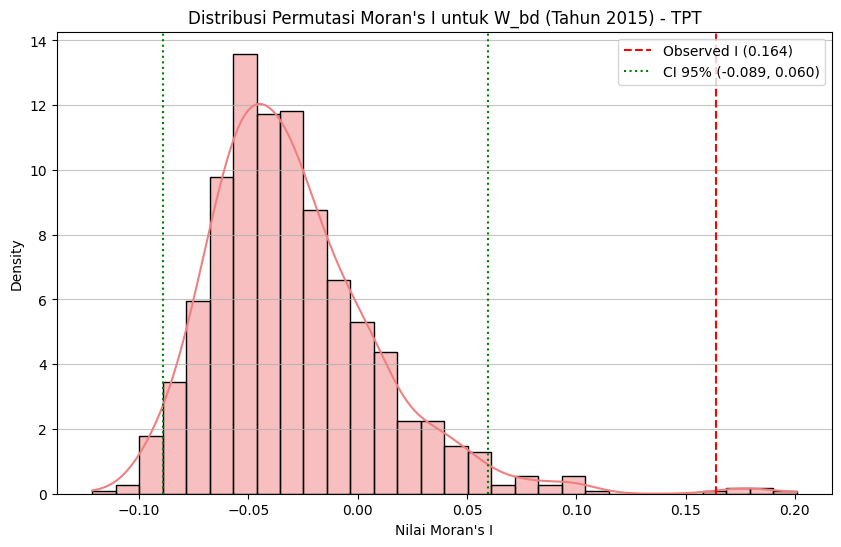

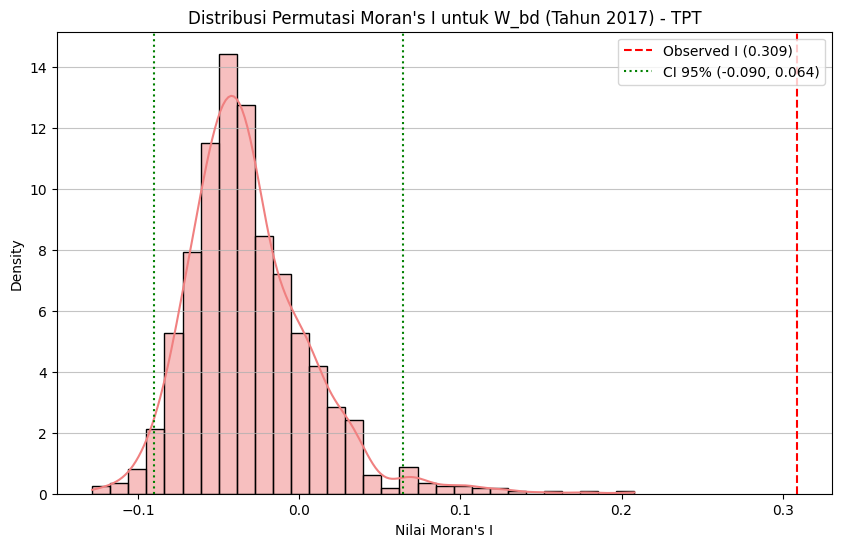

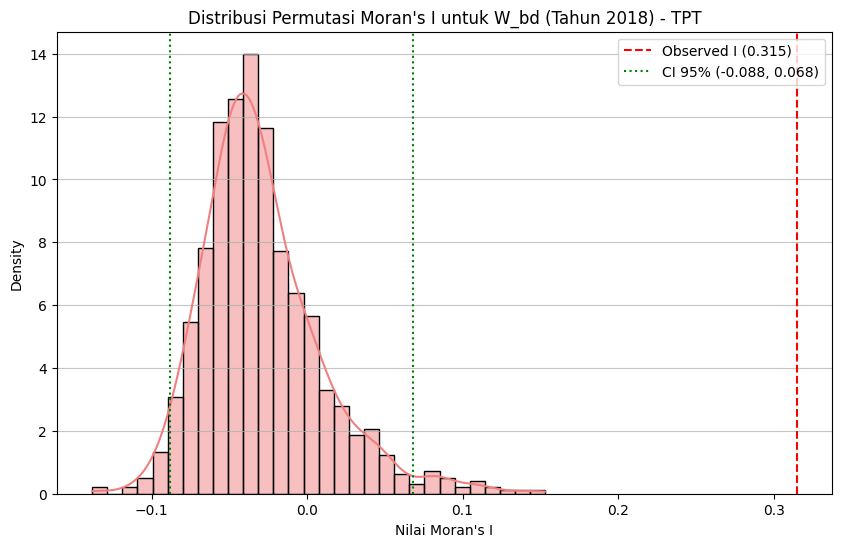

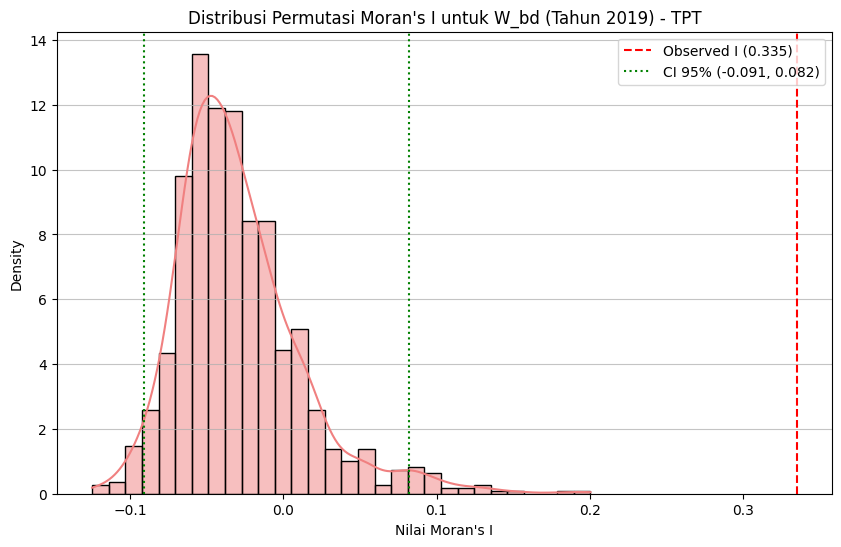

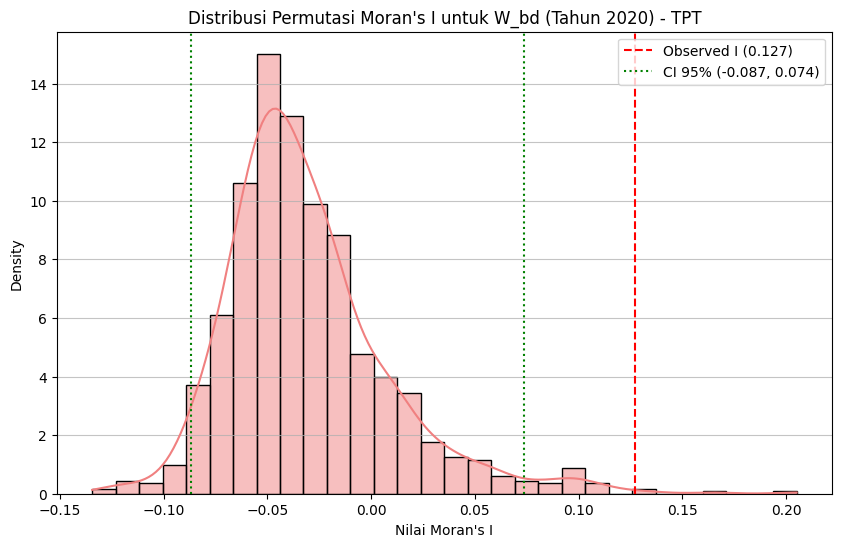

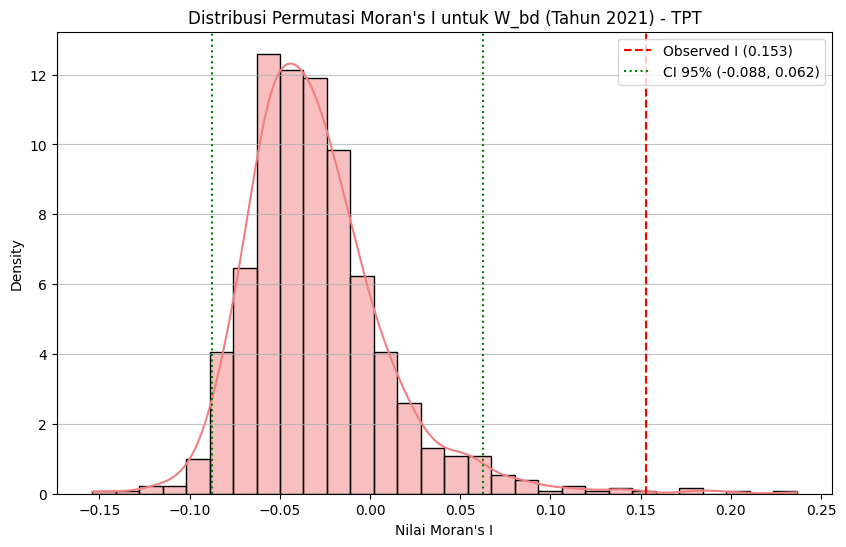

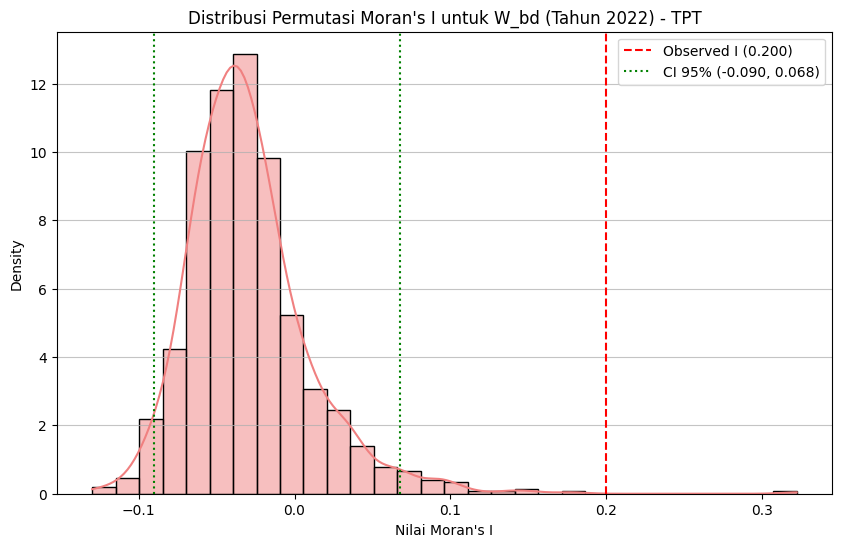

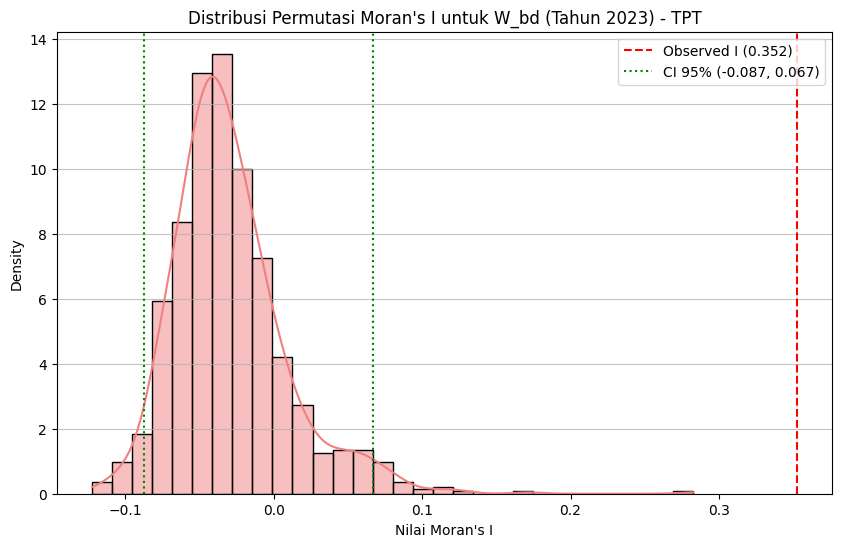

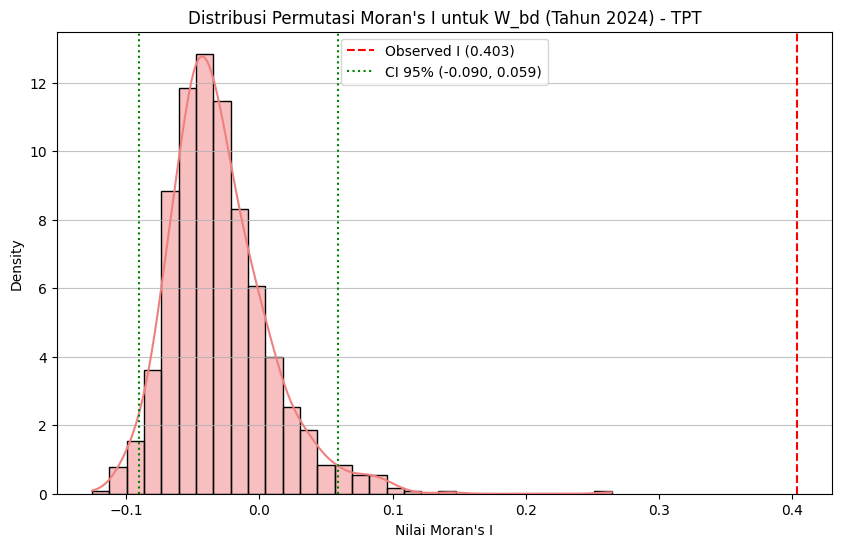

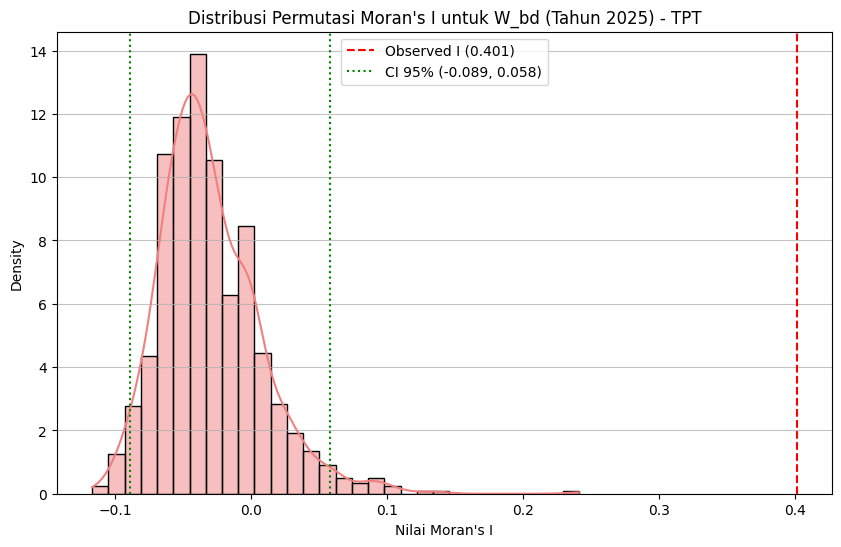

In [10]:
# --- Visualization for W_bd per year ---
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Tentukan bidang target yang ingin divisualisasikan ('TPT', 'Kesehatan', atau 'Pendidikan')
target_field = 'TPT'

# Load W_bd matrix once
W_bd_mat = pd.read_excel(W8_PATH, sheet_name='W_bd', header=None).to_numpy(dtype=float)

n_perm = 1000
seed = 2026 # Use the same seed for reproducibility

# Ambil dataframe dan hasil spesifik untuk target_field
df_target = dfs[target_field]
res_bd_year_df_target = all_res_bd_year[target_field]

for yr in sorted(df_target["Waktu"].unique()):
    df_y = df_target[df_target["Waktu"] == yr].copy()
    y_yr = df_y["Y"].astype(float).to_numpy()
    z_yr = (y_yr - y_yr.mean()) / y_yr.std(ddof=0)

    # Get observed I and CI for the current year from the target dataframe
    yearly_data = res_bd_year_df_target[res_bd_year_df_target['Year'] == yr].iloc[0]
    ob_I_bd = yearly_data['I_obs']
    ciL_bd = yearly_data['ci95_low']
    ciH_bd = yearly_data['ci95_high']

    # Regenerate permutation values for W_bd for plotting for the current year
    rng = np.random.default_rng(seed)
    I_perm_bd = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        z_perm = rng.permutation(z_yr)
        I_perm_bd[b] = moran_index(z_perm, W_bd_mat)

    plt.figure(figsize=(10, 6))
    sns.histplot(I_perm_bd, bins=30, kde=True, color='lightcoral', stat='density')
    plt.axvline(ob_I_bd, color='red', linestyle='--', label=f'Observed I ({ob_I_bd:.3f})')
    plt.axvline(ciL_bd, color='green', linestyle=':', label=f'CI 95% ({ciL_bd:.3f}, {ciH_bd:.3f})')
    plt.axvline(ciH_bd, color='green', linestyle=':')
    plt.title(f'Distribusi Permutasi Moran\'s I untuk W_bd (Tahun {yr}) - {target_field}')
    plt.xlabel('Nilai Moran\'s I')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(axis='y', alpha=0.75)
    plt.show()

## Year-over-Year Trends in Moran's I for W_bd

The following graph shows how Moran's I (`I_obs`) values ​​for the weighted `W_bd` have changed from 2018 to 2022, along with 95% confidence intervals.

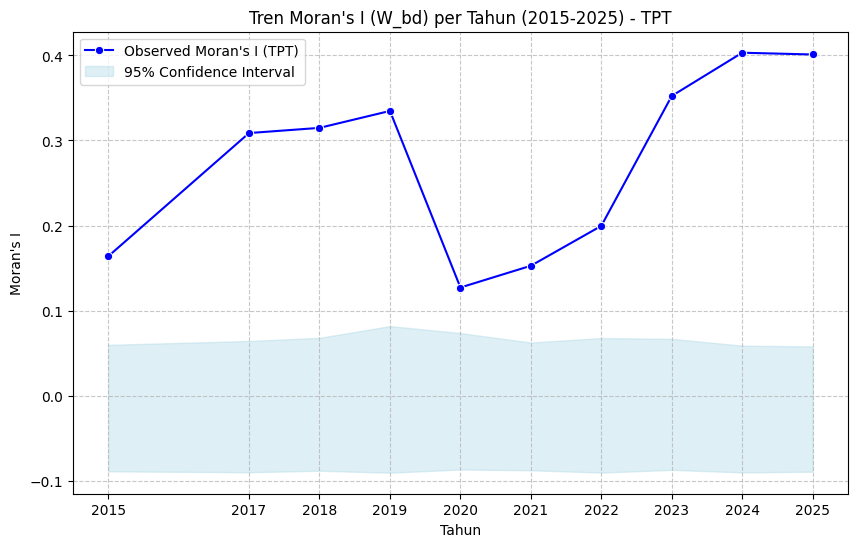

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pilih bidang target yang ingin divisualisasikan (opsi: 'TPT', 'Kesehatan', 'Pendidikan')
target_field = 'TPT'

# Mengambil data tren tahunan W_bd dari dictionary hasil
if 'all_res_bd_year' in globals() and target_field in all_res_bd_year:
    res_bd_year_df = all_res_bd_year[target_field]

    plt.figure(figsize=(10, 6))
    sns.lineplot(x='Year', y='I_obs', data=res_bd_year_df, marker='o', label=f"Observed Moran's I ({target_field})", color='blue')
    plt.fill_between(
        res_bd_year_df['Year'],
        res_bd_year_df['ci95_low'],
        res_bd_year_df['ci95_high'],
        color='lightblue', alpha=0.4, label='95% Confidence Interval'
    )

    plt.title(f"Tren Moran's I (W_bd) per Tahun (2015-2025) - {target_field}")
    plt.xlabel('Tahun')
    plt.ylabel("Moran's I")
    plt.xticks(res_bd_year_df['Year'])
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()
else:
    print(f"Data hasil untuk bidang '{target_field}' tidak ditemukan di 'all_res_bd_year'. Pastikan cell pengolahan data sudah dijalankan.")

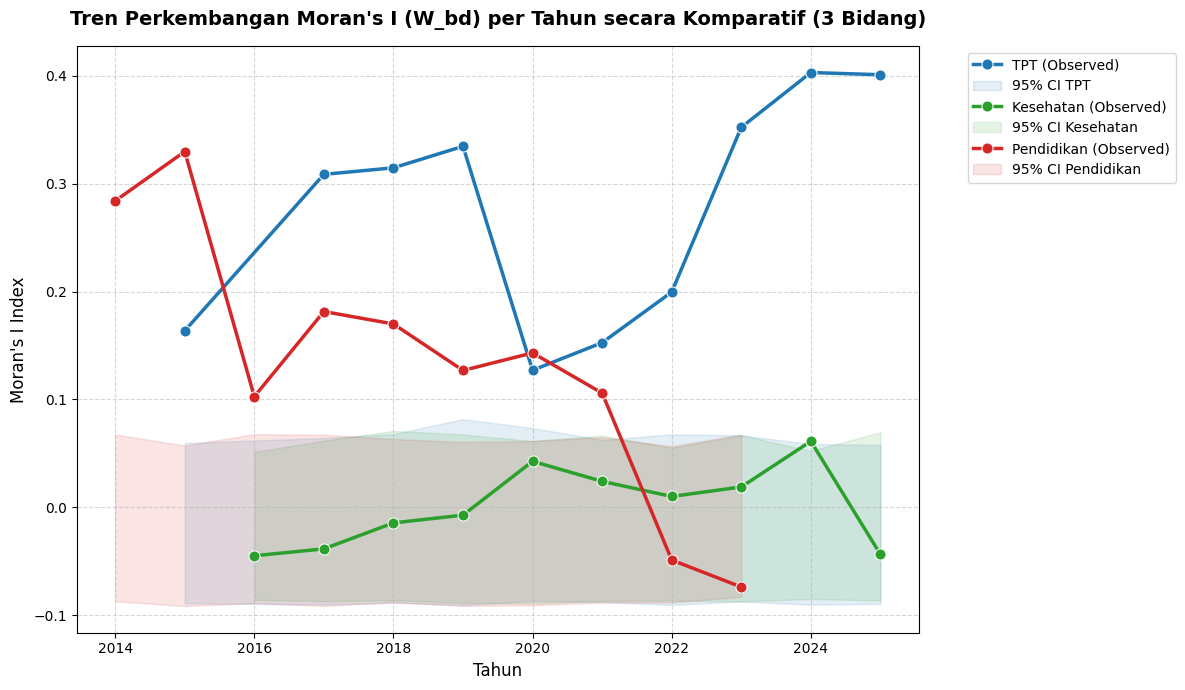

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Mempersiapkan plot komparatif untuk 3 bidang (TPT, Kesehatan, Pendidikan)
plt.figure(figsize=(12, 7))
colors = {'TPT': '#1f77b4', 'Kesehatan': '#2ca02c', 'Pendidikan': '#d62728'}

for field, res_df in all_res_bd_year.items():
    # Pastikan data diurutkan berdasarkan tahun
    res_sorted = res_df.sort_values('Year')

    # Plot garis tren utama
    sns.lineplot(
        x='Year',
        y='I_obs',
        data=res_sorted,
        marker='o',
        markersize=8,
        label=f"{field} (Observed)",
        color=colors[field],
        linewidth=2.5
    )
    # Plot area selang kepercayaan 95% (Confidence Interval)
    plt.fill_between(
        res_sorted['Year'],
        res_sorted['ci95_low'],
        res_sorted['ci95_high'],
        color=colors[field],
        alpha=0.12,
        label=f"95% CI {field}"
    )

plt.title("Tren Perkembangan Moran's I (W_bd) per Tahun secara Komparatif (3 Bidang)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tahun', fontsize=12)
plt.ylabel("Moran's I Index", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

## Visualization of Moran-2Di Permutation Distribution for Each W_ST Weight

The following is a histogram plot showing the distribution of Moran-2Di values from permutation simulations for each type of W_ST weight. The red dotted line shows the observed Moran-2Di (`I_obs`), and the green dotted line shows the lower and upper bounds of the 95% confidence interval (`ci95_low`, `ci95_high`).

Processing sheet: W_ST^Q


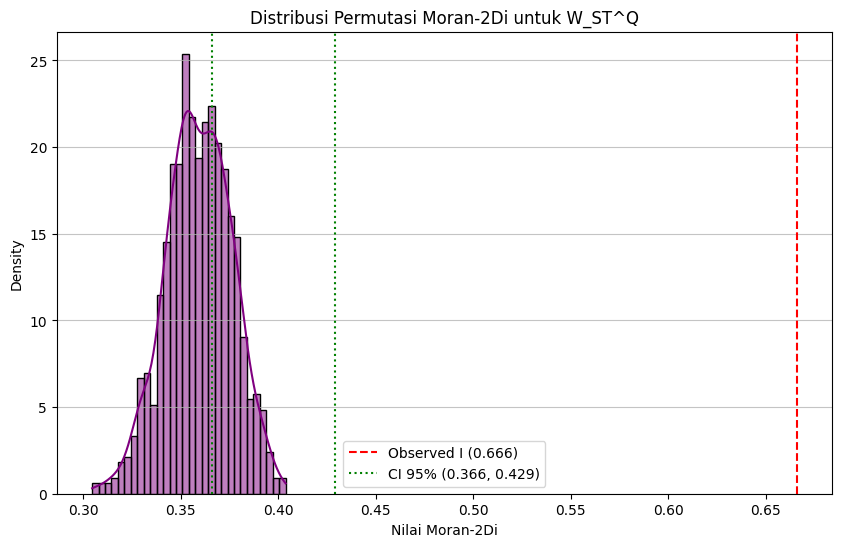

Processing sheet: W_ST^Q10


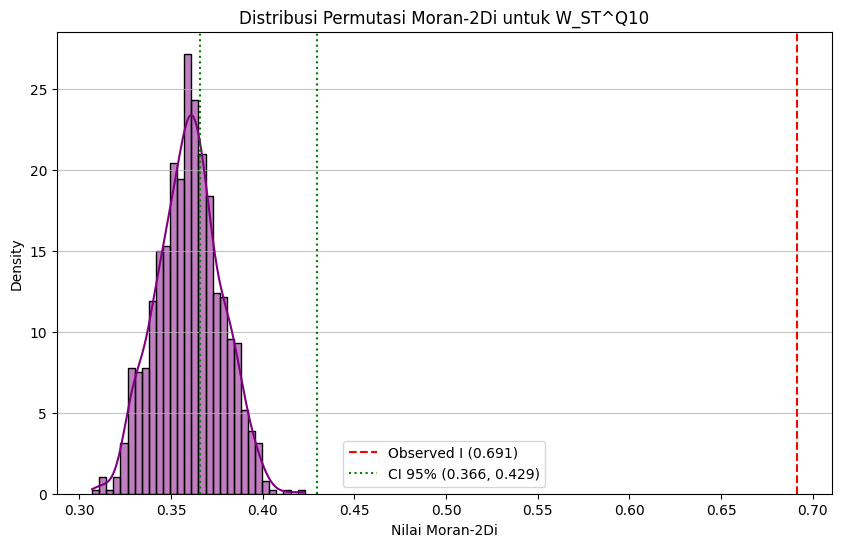

Processing sheet: W_ST^Q10q


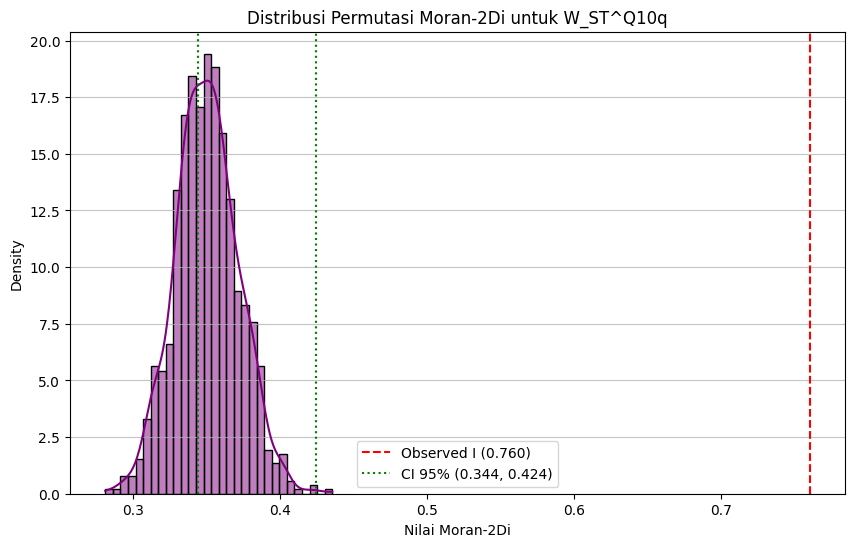

Processing sheet: W_ST^Q10r


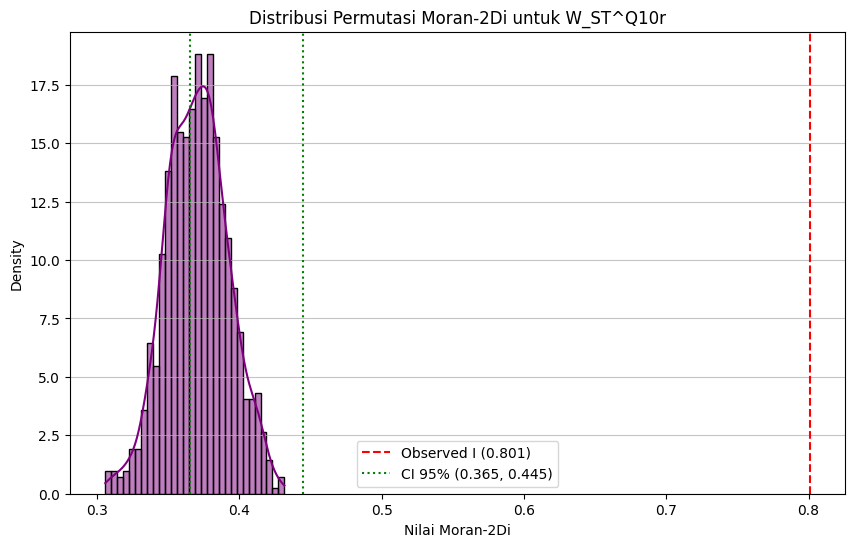

Processing sheet: W_ST^Qq


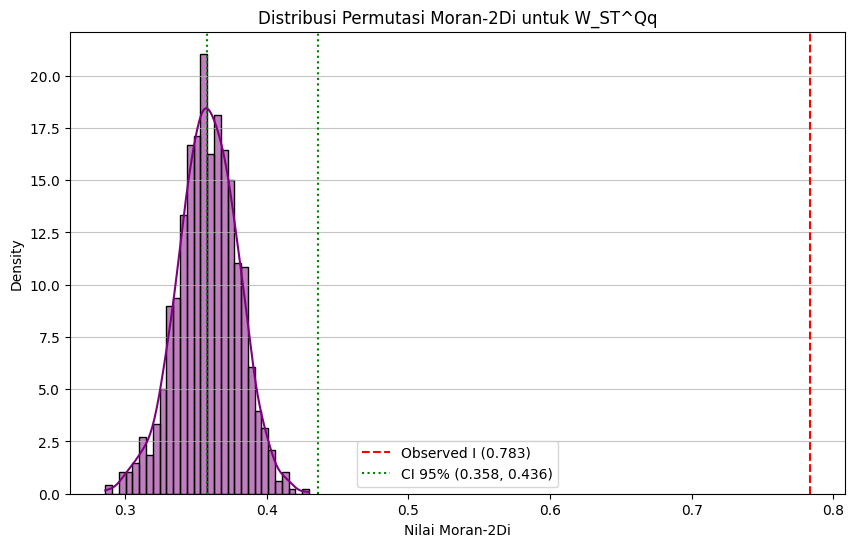

Processing sheet: W_ST^Qr


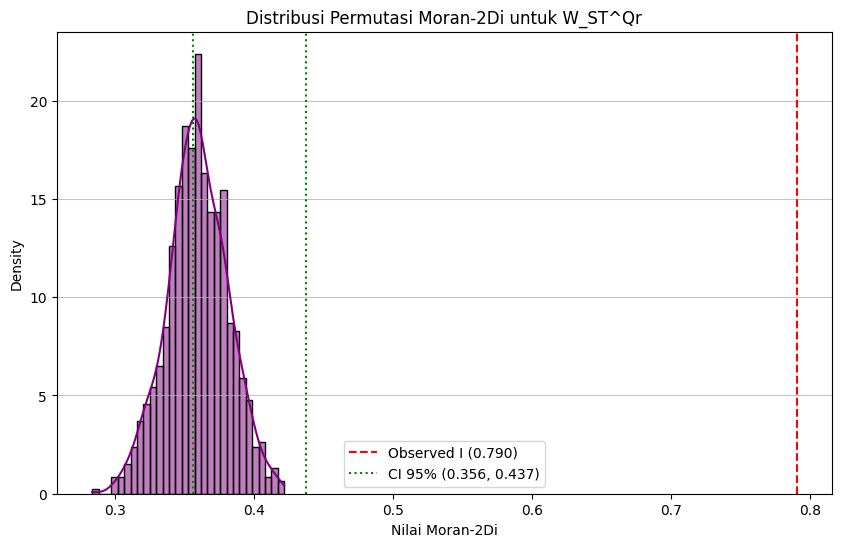

Processing sheet: W_ST^iq


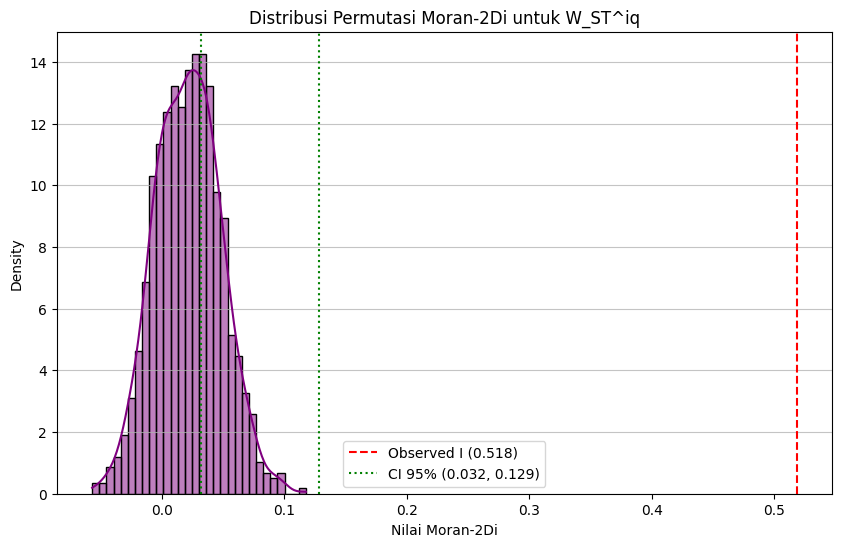

Processing sheet: W_bdst


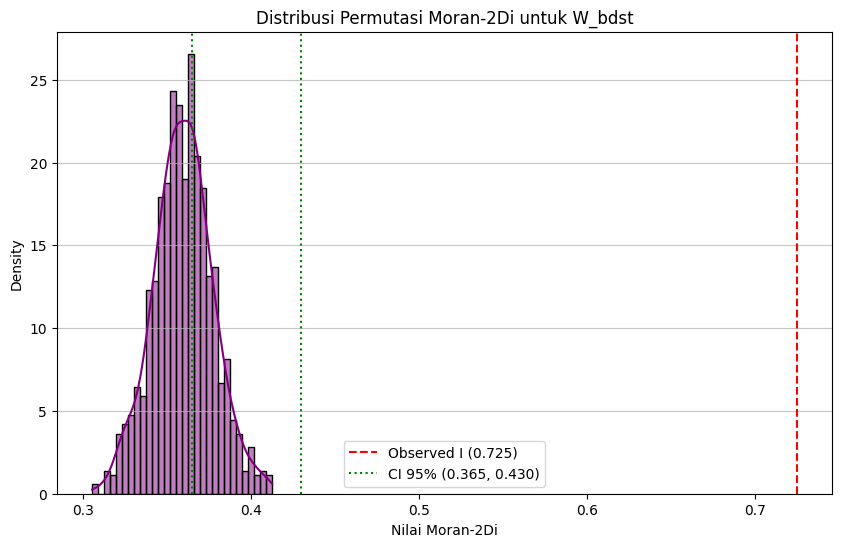

Processing sheet: Wseragam_diag1


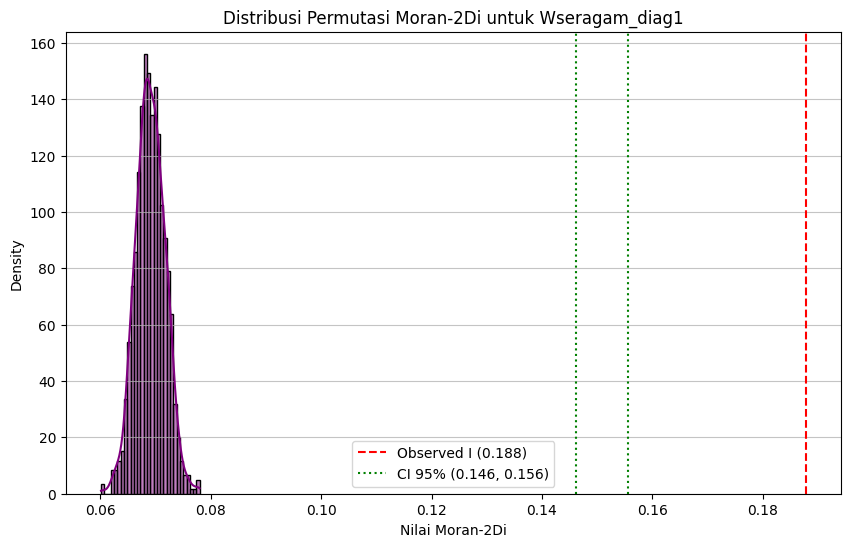

Processing sheet: Wseragam_diag0


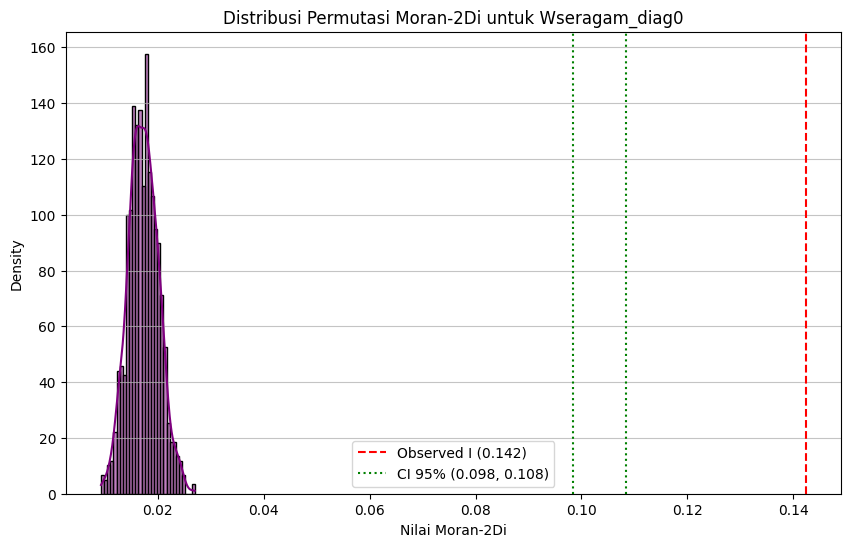

Processing sheet: Wacak_diag1


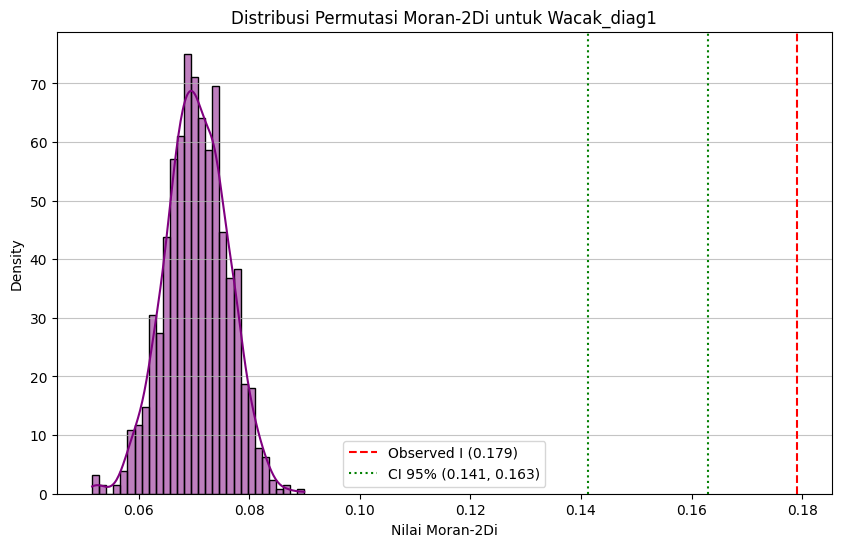

Processing sheet: Wacak_diag0


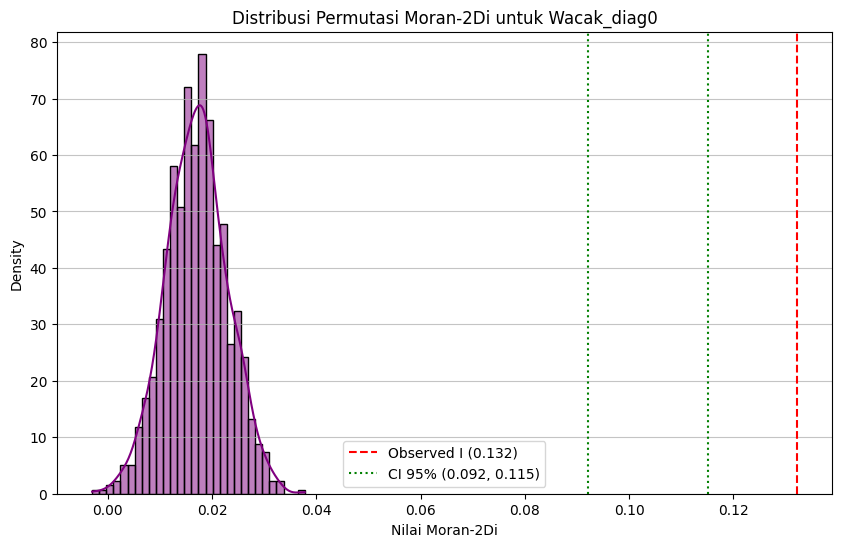

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for W_ST weights (exclude 'W_bd' which is handled separately)
w_st_sheets = [sh for sh in sheets_needed if sh != 'W_bd']

# Ensure N is available from previous cells
# N = len(z)
# years is also available from previous cells
# unique_years = np.unique(years)
# year_indices = {yr: np.where(years == yr)[0] for yr in unique_years}

n_perm = 1000
seed = 2026
rng = np.random.default_rng(seed)

for sh in w_st_sheets:
    print(f"Processing sheet: {sh}")
    Wmat = pd.read_excel(W8_PATH, sheet_name=sh, header=None).to_numpy(dtype=float)

    # Get observed I and CI for the current W_ST type from the dataframe
    w_st_data = res_st_df[res_st_df['Weight'] == sh].iloc[0]
    ob_I_st = w_st_data['I_obs']
    ciL_st = w_st_data['ci95_low']
    ciH_st = w_st_data['ci95_high']

    # Regenerate permutation values for the current W_ST for plotting
    I_perm_st = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        z_perm = z.copy()
        for yr, idx in year_indices.items():
            z_perm[idx] = rng.permutation(z_perm[idx])
        I_perm_st[b] = moran_index(z_perm, Wmat)

    plt.figure(figsize=(10, 6))
    sns.histplot(I_perm_st, bins=30, kde=True, color='purple', stat='density')
    plt.axvline(ob_I_st, color='red', linestyle='--', label=f'Observed I ({ob_I_st:.3f})')
    plt.axvline(ciL_st, color='green', linestyle=':', label=f'CI 95% ({ciL_st:.3f}, {ciH_st:.3f})')
    plt.axvline(ciH_st, color='green', linestyle=':')
    plt.title(f'Distribusi Permutasi Moran-2Di untuk {sh}')
    plt.xlabel('Nilai Moran-2Di')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(axis='y', alpha=0.75)
    plt.show()


## Summary Table of Observed Moran's I for All W_ST Weights

The following table summarizes the observed Moran's I, p-value, permutation mean and standard deviation, and 95% confidence interval for each type of W_ST weight.

In [14]:
display(res_st_df)

,Weight,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_ST^Q,0.665860,0.000999,0.397693,0.016116,0.366083,0.429262
1,W_ST^Q10,0.691172,0.000999,0.397706,0.016250,0.365648,0.429440
2,W_ST^Q10q,0.760292,0.000999,0.383351,0.020225,0.343675,0.424077
3,W_ST^Q10r,0.800831,0.000999,0.405870,0.020288,0.365316,0.444883
4,W_ST^Qq,0.783447,0.000999,0.397294,0.019991,0.358008,0.435997
5,W_ST^Qr,0.790093,0.000999,0.397269,0.020211,0.356497,0.437161
6,W_ST^iq,0.518330,0.000999,0.080711,0.024810,0.031863,0.128741
7,W_bdst,0.725056,0.000999,0.397678,0.016720,0.364863,0.429743
8,Wacak_diag0,0.132161,0.000999,0.103498,0.005800,0.092203,0.115227
9,Wacak_diag1,0.179013,0.000999,0.151896,0.005487,0.141211,0.162992


In [15]:
import pandas as pd

# Menampilkan tabel ringkasan hasil spasiotemporal untuk 3 bidang
for field in ['TPT', 'Kesehatan', 'Pendidikan']:
    print(f"\n=== TABEL RINGKASAN SPASIOTEMPORAL (W_ST) - BIDANG {field.upper()} ===")
    if field in all_res_st:
        df_display = all_res_st[field][["Weight", "I_obs", "p_value", "perm_mean", "perm_std", "ci95_low", "ci95_high"]]
        display(df_display)
    else:
        print(f"Data untuk bidang {field} tidak ditemukan.")


=== TABEL RINGKASAN SPASIOTEMPORAL (W_ST) - BIDANG TPT ===


,Weight,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_ST^Q,0.665860,0.000999,0.397693,0.016116,0.366083,0.429262
1,W_ST^Q10,0.691172,0.000999,0.397706,0.016250,0.365648,0.429440
2,W_ST^Q10q,0.760292,0.000999,0.383351,0.020225,0.343675,0.424077
3,W_ST^Q10r,0.800831,0.000999,0.405870,0.020288,0.365316,0.444883
4,W_ST^Qq,0.783447,0.000999,0.397294,0.019991,0.358008,0.435997
5,W_ST^Qr,0.790093,0.000999,0.397269,0.020211,0.356497,0.437161
6,W_ST^iq,0.518330,0.000999,0.080711,0.024810,0.031863,0.128741
7,W_bdst,0.725056,0.000999,0.397678,0.016720,0.364863,0.429743
8,Wacak_diag0,0.132161,0.000999,0.103498,0.005800,0.092203,0.115227
9,Wacak_diag1,0.179013,0.000999,0.151896,0.005487,0.141211,0.162992



=== TABEL RINGKASAN SPASIOTEMPORAL (W_ST) - BIDANG KESEHATAN ===


,Weight,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_ST^Q,0.553596,0.000999,0.377667,0.015546,0.349244,0.407937
1,W_ST^Q10,0.558554,0.000999,0.377563,0.015723,0.348629,0.408148
2,W_ST^Q10q,0.584418,0.000999,0.367891,0.020175,0.328801,0.408460
3,W_ST^Q10r,0.613127,0.000999,0.385931,0.020525,0.346511,0.427282
4,W_ST^Qq,0.598544,0.000999,0.378055,0.020021,0.339196,0.417753
5,W_ST^Qr,0.598873,0.000999,0.378197,0.020534,0.338236,0.419459
6,W_ST^iq,0.326099,0.000999,0.049920,0.023988,0.005735,0.096812
7,W_bdst,0.561508,0.000999,0.377519,0.016022,0.347277,0.408624
8,Wacak_diag0,0.144273,0.000999,0.107083,0.006043,0.095443,0.118770
9,Wacak_diag1,0.190470,0.000999,0.155288,0.005717,0.144277,0.166344



=== TABEL RINGKASAN SPASIOTEMPORAL (W_ST) - BIDANG PENDIDIKAN ===


,Weight,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_ST^Q,0.590423,0.000999,0.359185,0.016877,0.325460,0.391228
1,W_ST^Q10,0.616243,0.000999,0.359152,0.016947,0.324926,0.391180
2,W_ST^Q10q,0.683059,0.000999,0.350173,0.021115,0.311746,0.391287
3,W_ST^Q10r,0.713241,0.000999,0.369611,0.021711,0.328985,0.410185
4,W_ST^Qq,0.700812,0.000999,0.359361,0.020979,0.319754,0.400289
5,W_ST^Qr,0.713659,0.000999,0.359438,0.021710,0.319468,0.399556
6,W_ST^iq,0.413887,0.000999,0.021838,0.025844,-0.029934,0.071056
7,W_bdst,0.636241,0.000999,0.359163,0.017312,0.324938,0.391173
8,Wacak_diag0,0.040914,0.000999,0.017177,0.006046,0.004700,0.028418
9,Wacak_diag1,0.092691,0.000999,0.070236,0.005720,0.058432,0.080870


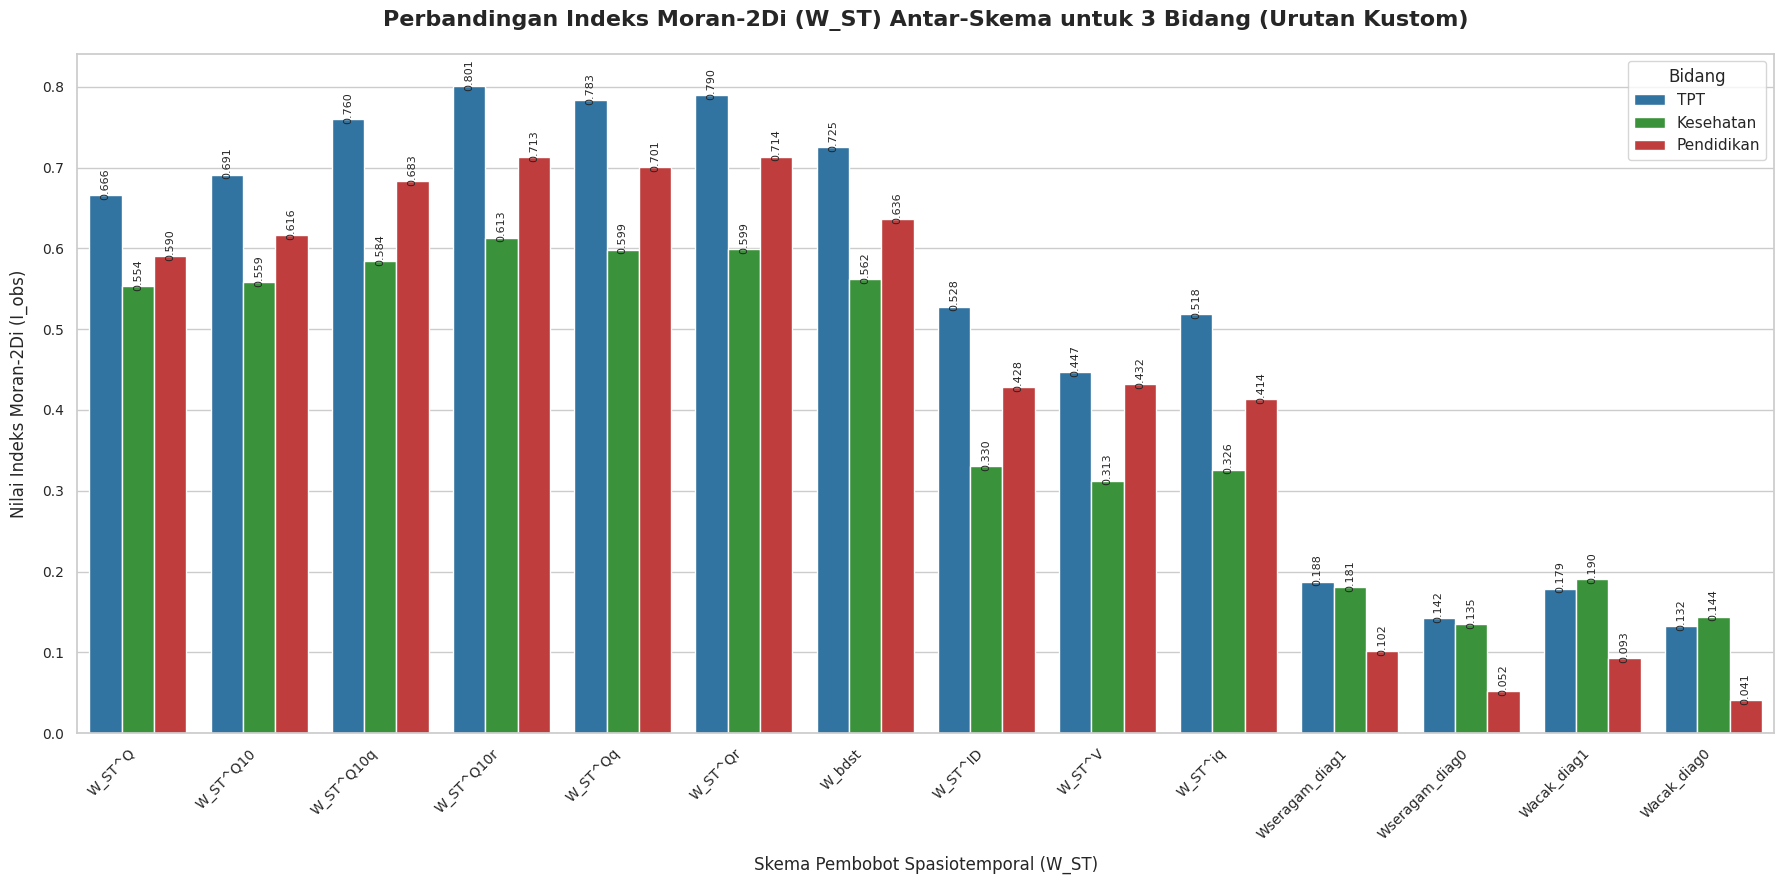

In [16]:
#VISUALISASI INDEKS MORAN-2Di
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memastikan all_res_st terdefinisi (bila runtime terputus/belum dijalankan ulang)
try:
    all_res_st_clean = {k: v.copy() for k, v in all_res_st.items()}
except NameError:
    all_res_st_clean = {"TPT": pd.DataFrame(), "Kesehatan": pd.DataFrame(), "Pendidikan": pd.DataFrame()}

# Data tambahan untuk W_ST^V dan W_ST^ID sesuai spesifikasi user
manual_data = [
    # W_ST^V
    {"Field": "TPT", "Weight": "W_ST^V", "I_obs": 0.4467584034207757, "perm_mean": 0.08066889649692185, "p_value": 0.000999000999000999, "ci95_low": 0.0328059049106162, "ci95_high": 0.12732790463909918},
    {"Field": "Kesehatan", "Weight": "W_ST^V", "I_obs": 0.3125917091379029, "perm_mean": 0.05021601797047724, "p_value": 0.000999000999000999, "ci95_low": 0.006936050628679968, "ci95_high": 0.09600822905872146},
    {"Field": "Pendidikan", "Weight": "W_ST^V", "I_obs": 0.43229245351089673, "perm_mean": 0.021882033485870662, "p_value": 0.000999000999000999, "ci95_low": -0.028742892901651117, "ci95_high": 0.07233766865016329},
    # W_ST^ID
    {"Field": "TPT", "Weight": "W_ST^ID", "I_obs": 0.5280199358657502, "perm_mean": 0.0805388797958629, "p_value": 0.000999000999000999, "ci95_low": 0.03172454983774812, "ci95_high": 0.1279370055029312},
    {"Field": "Kesehatan", "Weight": "W_ST^ID", "I_obs": 0.33032181321004184, "perm_mean": 0.05017617515110938, "p_value": 0.000999000999000999, "ci95_low": 0.005097431293264511, "ci95_high": 0.09845032898319643},
    {"Field": "Pendidikan", "Weight": "W_ST^ID", "I_obs": 0.4284683091801527, "perm_mean": 0.02197359062324661, "p_value": 0.000999000999000999, "ci95_low": -0.030736130547665903, "ci95_high": 0.07120243061681751}
]
df_manual = pd.DataFrame(manual_data)

# Menggabungkan data dari all_res_st_clean (jika ada data sebelumnya)
plot_data_list = []
for field in ['TPT', 'Kesehatan', 'Pendidikan']:
    if field in all_res_st_clean and not all_res_st_clean[field].empty:
        temp_df = all_res_st_clean[field].copy()
        temp_df['Field'] = field
        plot_data_list.append(temp_df)

if plot_data_list:
    df_plot_existing = pd.concat(plot_data_list, ignore_index=True)
    # Mengubah nama label 'W_ST^ik(ItWs)' menjadi 'W_ST^iq'
    df_plot_existing['Weight'] = df_plot_existing['Weight'].replace({"W_ST^ik(ItWs)": "W_ST^iq"})
    # Pastikan tidak ada duplikasi data W_ST^V atau W_ST^ID yang dimasukkan manual
    df_plot_existing = df_plot_existing[~df_plot_existing['Weight'].isin(['W_ST^V', 'W_ST^ID'])]
    df_plot_all = pd.concat([df_plot_existing, df_manual], ignore_index=True)
else:
    df_plot_all = df_manual

if not df_plot_all.empty:
    # Ringkas label untuk visualisasi agar seragam
    rename_dict = {
        "Wacak_diag1": "Wacak_diag1",
        "Wacak_diag0": "Wacak_diag0"
    }
    df_plot_all['Weight'] = df_plot_all['Weight'].replace(rename_dict)

# Urutan spesifik dengan pelabelan revisi yang konsisten
specified_order = [
    "W_ST^Q",
    "W_ST^Q10",
    "W_ST^Q10q",
    "W_ST^Q10r",
    "W_ST^Qq",
    "W_ST^Qr",
    "W_bdst",
    "W_ST^ID",
    "W_ST^V",
    "W_ST^iq",
    "Wseragam_diag1",
    "Wseragam_diag0",
    "Wacak_diag1",
    "Wacak_diag0"
]

if not df_plot_all.empty:
    # Setup style visualisasi
    plt.figure(figsize=(18, 9))
    sns.set_theme(style="whitegrid")

    # Membuat Grouped Bar Chart dengan urutan spesifik
    ax = sns.barplot(
        x='Weight',
        y='I_obs',
        hue='Field',
        data=df_plot_all,
        order=specified_order,
        palette={'TPT': '#1f77b4', 'Kesehatan': '#2ca02c', 'Pendidikan': '#d62728'}
    )

    # Pengaturan Judul dan Label
    plt.title("Perbandingan Indeks Moran-2Di (W_ST) Antar-Skema untuk 3 Bidang (Urutan Kustom)", fontsize=16, fontweight='bold', pad=20)
    plt.xlabel("Skema Pembobot Spasiotemporal (W_ST)", fontsize=12, labelpad=10)
    plt.ylabel("Nilai Indeks Moran-2Di (I_obs)", fontsize=12, labelpad=10)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)
    plt.legend(title="Bidang", fontsize=11, title_fontsize=12, loc='upper right')

    # Menambahkan nilai di atas batang
    for p in ax.patches:
        height = p.get_height()
        if pd.notna(height) and height > 0:
            ax.annotate(
                f"{height:.3f}",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points',
                fontsize=8, rotation=90
            )

    plt.tight_layout()
    plt.show()
else:
    print("Data hasil visualisasi kosong.")